In [1]:
from itertools import cycle

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, Rectangle

import arsenal_gear as ag

### Available parameter space for elemental yields

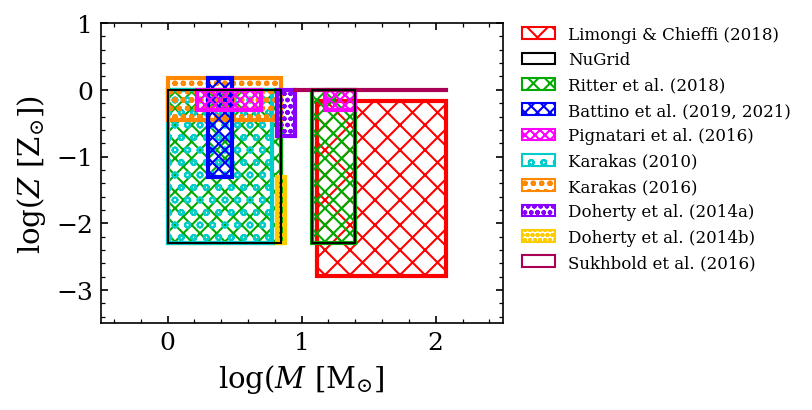

In [2]:
Zsun = 0.02
colors = cycle(['#FF0000','#00AA00','#0000FF','#FF00FF','#00CCCC','#FF8800','#8800FF','#FFCC00','#AA0055'])
hatches = cycle(['xx', 'xxx', 'xxxx', 'xxxxx', 'oo', 'ooo', 'oooo', 'ooooo'])
zorders = cycle([1,10,2,6,7,3,4,5,8,9])
handles = []

fig = plt.figure()
plt.xlabel(r"$\log(M\ [{\rm M}_{\odot}$]")
plt.ylabel(r"$\log(Z\ [{\rm Z}_{\odot}$])")
plt.xlim(-0.5, 2.5)
plt.ylim(-3.5, 1)


def plot_region(mass, metal, color, hatch):

    x = np.log10(mass)
    y = np.log10(metal / Zsun)

    xmin, xmax = np.min(x), np.max(x)
    ymin, ymax = np.min(y), np.max(y)
    if xmin == xmax and ymin == ymax:
        # Single point
        plt.plot(xmin, ymin, 'o', color=color, markersize=5, zorder=zorder)
    elif xmin == xmax:
        # Single mass
        plt.plot([xmin, xmax], [ymin, ymax], color=color, linewidth=lw, zorder=zorder)
    elif ymin == ymax:
        # Single metallicity
        plt.plot([xmin, xmax], [ymin, ymax], color=color, linewidth=lw, zorder=zorder)
    else:
        rect = Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
            facecolor='none', edgecolor=color, hatch=hatch, linewidth=lw, zorder=zorder)
        plt.gca().add_patch(rect)


for name in ag.element_yields.__all__:
    zorder = next(zorders)
    if name == 'NuGrid':
        color = 'k'
        hatch = ''
        lw=1
    elif name == 'Sukhbold2016':
        color = next(colors)
        hatch = ''
        lw=2
    else:
        color = next(colors)
        hatch = next(hatches)
        lw=2
    yld = getattr(ag.element_yields, name)()
    
    mass = yld.mass
    metal = yld.metal

    # Convert to list if single value
    if isinstance(mass, float):
        mass = np.array(mass)
    if isinstance(metal, float):
        metal = np.array(metal)

    # Check if multiple parameter ranges
    if isinstance(mass, list):
        for m in mass:
            plot_region(m, metal, color, hatch)
    else:
        plot_region(mass, metal, color, hatch)

    handles.append(
        Patch(facecolor='none', edgecolor=color, hatch=hatch, label=yld.name))
    
plt.legend(handles=handles, fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1.04), frameon=False)
plt.show()

### Example of how yield class is used

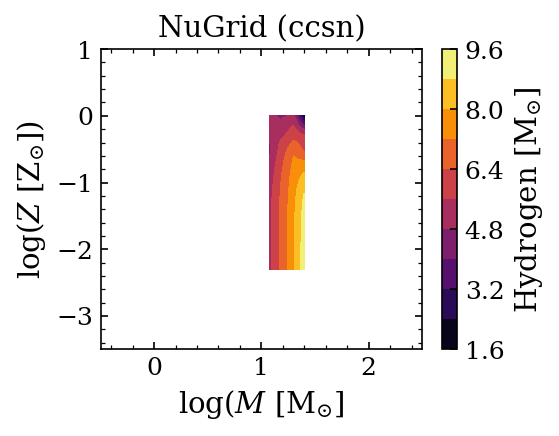

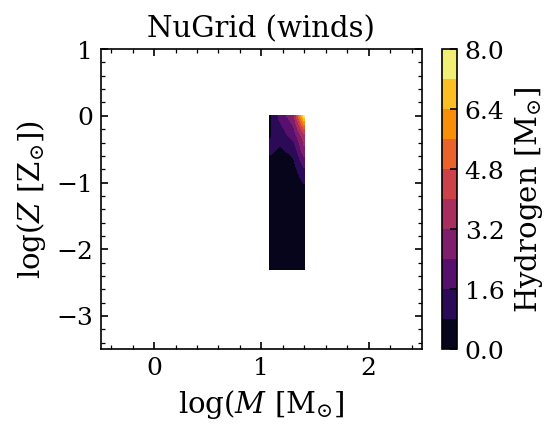

In [3]:
yields = ag.element_yields.NuGrid()
mass = np.logspace(np.log10(np.min(yields.mass[1])), np.log10(np.max(yields.mass[1])), 64)
met= np.logspace(np.log10(np.min(yields.metal)), np.log10(np.max(yields.metal)), 64)

arr_mass, arr_met = np.meshgrid(mass, met)
(Mtot,Nstar) = (np.sum(arr_mass), arr_mass.size)
(mmin, mmax) = (np.min(mass), np.max(mass))
metallicity = arr_met.flatten() * u.dimensionless_unscaled
masses = arr_mass.flatten() * u.Msun
rotation = 0*u.dimensionless_unscaled

stars = ag.formation.SinglePop(
    Mtot=Mtot,
    tform=0,
    Nstar=Nstar,
    metallicity=metallicity,
    rotation=rotation,
    imf=None,
    mmin=mmin,
    mmax=mmax,
    masses=masses,
    discrete=True)

fig = plt.figure()
plt.xlabel(r"$\log(M\ [{\rm M}_{\odot}$]")
plt.ylabel(r"$\log(Z\ [{\rm Z}_{\odot}$])")
plt.xlim(-0.5,2.5)
plt.ylim(-3.5, 1)

yld = yields.ccsn_yields('H', stars, interpolate='linear')
yld = yld['H'].reshape(arr_mass.shape).value
plt.title(yields.name+" (ccsn)")
cf = plt.contourf(np.log10(arr_mass), np.log10(arr_met/0.02), yld, levels=10, cmap='inferno')
plt.colorbar(cf, label=r'Hydrogen [M$_{\odot}$]')

plt.show()

fig = plt.figure()
plt.xlabel(r"$\log(M\ [{\rm M}_{\odot}$]")
plt.ylabel(r"$\log(Z\ [{\rm Z}_{\odot}$])")
plt.xlim(-0.5,2.5)
plt.ylim(-3.5, 1)
yld = yields.wind_yields('H', stars, interpolate='linear')
yld = yld['H'].reshape(arr_mass.shape).value
plt.title(yields.name+" (winds)")
cf = plt.contourf(np.log10(arr_mass), np.log10(arr_met/0.02), yld, levels=10, cmap='inferno')
plt.colorbar(cf, label=r'Hydrogen [M$_{\odot}$]')

plt.show()

